# Ojo en órbita

Estudiamos si podemos descubrir usos del suelo con imágenes de satélite. Trabajamos con **8.000 parches RGB de 64 × 64 píxeles, 800 por clase**, seleccionados de [EuroSAT](https://github.com/phelber/EuroSAT).


## Dataset EuroSAT RGB

Descargamos el [subconjunto EuroSAT RGB en formato ZIP](https://upm365-my.sharepoint.com/:u:/g/personal/anton_pogromskyy_alumnos_upm_es/IQCVHas6nvyzQ5q_0426Mu43AUznmqcDQGyoeKBE_wm5yg8?e=rYR1dK) y lo extraemos en `data/EuroSAT_RGB_800/`. Cada JPG tiene un TIFF del mismo parche en el subconjunto multiespectral. Podremos usarlo más adelante para probar qué aporta la banda de infrarrojo cercano B08.


In [1]:
from pathlib import Path
import subprocess
from tempfile import TemporaryDirectory
from zipfile import BadZipFile, ZipFile, is_zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.stats import kurtosis, skew

In [2]:
RGB_DATASET_URL = (
    "https://upm365-my.sharepoint.com/:u:/g/personal/"
    "anton_pogromskyy_alumnos_upm_es/"
    "IQCVHas6nvyzQ5q_0426Mu43AUznmqcDQGyoeKBE_wm5yg8?e=rYR1dK&download=1"
)
EMBEDDINGS_URL = "https://upm365-my.sharepoint.com/:u:/g/personal/anton_pogromskyy_alumnos_upm_es/IQCNndBnJCd1RaWCgisxMQwTAfoenZTg5pFc5_1RbkJLixM?e=THLtSs&download=1"

DATA_DIR = Path("data")
RGB_DIR = DATA_DIR / "EuroSAT_RGB_800"
RGB_ARCHIVE_PATH = DATA_DIR / "EuroSAT_RGB_800.zip"

DATA_DIR.mkdir(parents=True, exist_ok=True)

### Características precalculadas

Al inicio comprobamos los CSV de características y los pares de embeddings e índices en `results/`. Si falta algún archivo, descargamos el ZIP de OneDrive para recuperarlo. Cada sección calcula sus características si siguen faltando.


In [3]:
features_dir = Path("results")
features_dir.mkdir(exist_ok=True)
spectral_path = features_dir / "spectral_features.csv"
haralick_path = features_dir / "haralick_features.csv"
lbp_path = features_dir / "lbp_features.csv"
embedding_models = ("resnet50", "clip")


def embedding_files(model):
    return (features_dir / f"{model}_embeddings.npy", features_dir / f"{model}_index.csv")


def embeddings_available(model):
    return all(path.is_file() for path in embedding_files(model))


feature_groups = [
    (spectral_path,),
    (haralick_path,),
    (lbp_path,),
    *(embedding_files(model) for model in embedding_models),
]


missing_groups = [paths for paths in feature_groups if not all(path.is_file() for path in paths)]
if missing_groups and EMBEDDINGS_URL:
    try:
        with TemporaryDirectory(dir=features_dir) as temp_dir:
            temp_dir = Path(temp_dir)
            downloaded_archive = temp_dir / "features_eurosat.zip"
            subprocess.run(
                ["curl", "-fsSL", "-b", "", "--connect-timeout", "15", "--max-time", "300",
                 EMBEDDINGS_URL, "-o", str(downloaded_archive)],
                check=True,
            )

            with ZipFile(downloaded_archive) as archive:
                members = set(archive.namelist())
                for paths in missing_groups:
                    if all(path.as_posix() in members for path in paths):
                        for path in paths:
                            archive.extract(path.as_posix(), temp_dir)
                        for path in paths:
                            (temp_dir / path).replace(path)
    except (BadZipFile, OSError, subprocess.CalledProcessError) as error:
        print(f"No se pudieron recuperar las características precalculadas: {error}")


### Descarga y extracción

Si ya hay 8.000 JPG extraídos, los reutilizamos. En caso contrario, extraemos el ZIP local o lo descargamos desde OneDrive si hace falta.


In [4]:
rgb_paths = sorted(RGB_DIR.glob("*/*.jpg"))

if len(rgb_paths) != 8000:
    if not is_zipfile(RGB_ARCHIVE_PATH):
        subprocess.run(
            ["curl", "-fsSL", "-b", "", RGB_DATASET_URL, "-o", str(RGB_ARCHIVE_PATH)],
            check=True,
        )

    with ZipFile(RGB_ARCHIVE_PATH) as archive:
        archive.extractall(DATA_DIR)

    rgb_paths = sorted(RGB_DIR.glob("*/*.jpg"))

if len(rgb_paths) != 8000:
    raise ValueError(f"Expected 8,000 JPG files, found {len(rgb_paths):,}.")

print(f"Dataset ready: {len(rgb_paths):,} images.")


Dataset ready: 8,000 images.


## Apartado A. Extracción de características

Calcularemos una fila de características por parche. Empezamos con los cuatro momentos de cada canal RGB de una imagen para comprobar el procedimiento. Después lo aplicaremos a todo el subconjunto y añadiremos los momentos en HSV y Lab.


In [5]:
image_path = rgb_paths[0]

with Image.open(image_path) as image:
    rgb = np.asarray(image.convert("RGB"), dtype=np.float64)

print("Image:", image_path.name)
print("RGB shape:", rgb.shape)
print(f"Value range: {rgb.min():.0f} to {rgb.max():.0f}")


Image: AnnualCrop_1.jpg
RGB shape: (64, 64, 3)
Value range: 82 to 204


In [6]:
# Arrange pixels as rows and RGB channels as columns.
pixels = rgb.reshape(-1, 3)
print("Pixels shape:", pixels.shape)

summary_rgb = pd.DataFrame(
    {
        "mean": pixels.mean(axis=0),
        "std": pixels.std(axis=0, ddof=0),
        "skewness": skew(pixels, axis=0, bias=True),
        "excess_kurtosis": kurtosis(pixels, axis=0, fisher=True, bias=True),
    },
    index=["R", "G", "B"],
)

display(summary_rgb.round(3))


Pixels shape: (4096, 3)


,mean,std,skewness,excess_kurtosis
R,109.109,15.522,2.545,8.976
G,97.438,9.320,2.435,8.546
B,104.854,6.950,2.081,7.067


En `AnnualCrop_1.jpg`, el rojo tiene la mayor media (109,11) y la mayor desviación típica (15,52). El azul tiene la menor dispersión (6,95). Los tres canales muestran asimetría positiva y exceso de curtosis positivo. En los histogramas se observa la cola hacia intensidades altas. Usamos la escala original de los JPG, de 0 a 255, y los mismos intervalos en los tres canales.


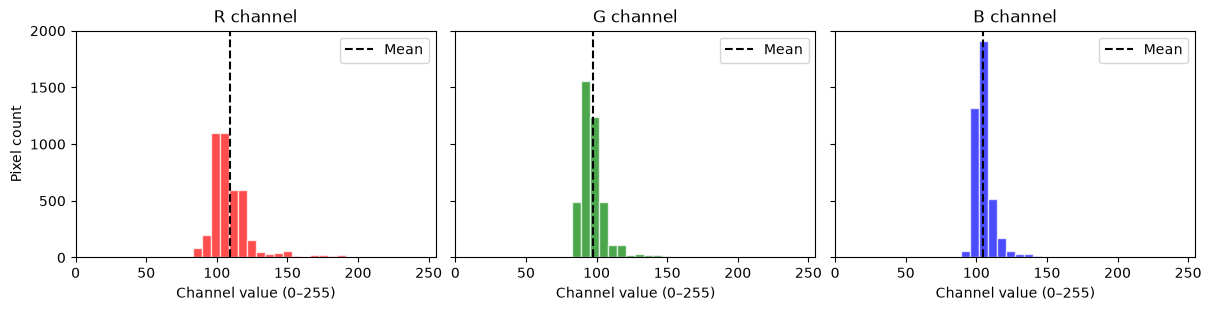

In [7]:
channel_names = ["R", "G", "B"]
channel_colors = ["red", "green", "blue"]
bin_edges = np.linspace(0, 255, 41)

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharex=True, sharey=True, layout="constrained")

for channel_index, (ax, name, color) in enumerate(
    zip(axes, channel_names, channel_colors)
):
    values = pixels[:, channel_index]
    ax.hist(values, bins=bin_edges, color=color, alpha=0.7, edgecolor="white")
    ax.axvline(values.mean(), color="black", linestyle="--", label="Mean")

    ax.set_title(f"{name} channel")
    ax.set_xlabel("Channel value (0–255)")
    ax.set_xlim(0, 255)
    ax.legend()

axes[0].set_ylabel("Pixel count")
plt.show()

### Características RGB

In [8]:
def color_moments(image, color_space, channel_names):
    pixels = image.reshape(-1, len(channel_names))

    statistics = {
        "mean": pixels.mean(axis=0),
        "std": pixels.std(axis=0, ddof=0),
        "skewness": skew(pixels, axis=0, bias=True),
        "excess_kurtosis": kurtosis(pixels, axis=0, fisher=True, bias=True),
    }

    features = {}
    for channel_index, channel_name in enumerate(channel_names):
        for statistic_name, values in statistics.items():
            column_name = f"{color_space}_{channel_name}_{statistic_name}"
            features[column_name] = values[channel_index]

    return features


def select_color_space(features, prefix):
    columns = [column for column in features if column.startswith(f"{prefix}_")]
    return features[["class_name", "patch_id", *columns]]


In [9]:
spectral_features = pd.read_csv(spectral_path) if spectral_path.is_file() else None

if spectral_features is not None:
    rgb_features = select_color_space(spectral_features, "RGB")
else:
    rows = []

    for image_path in rgb_paths:
        with Image.open(image_path) as image:
            rgb_image = np.asarray(image.convert("RGB"), dtype=np.float64)

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem,
        }

        rgb_moments = color_moments(rgb_image, "RGB", ("R", "G", "B"))
        row.update(rgb_moments)
        rows.append(row)

    rgb_features = pd.DataFrame(rows)

print("Table shape:", rgb_features.shape)
display(rgb_features.head().round(3))

Table shape: (8000, 14)


,class_name,patch_id,RGB_R_mean,RGB_R_std,RGB_R_skewness,RGB_R_excess_kurtosis,RGB_G_mean,RGB_G_std,RGB_G_skewness,RGB_G_excess_kurtosis,RGB_B_mean,RGB_B_std,RGB_B_skewness,RGB_B_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,109.109,15.522,2.545,8.976,97.438,9.320,2.435,8.546,104.854,6.950,2.081,7.067
1,AnnualCrop,AnnualCrop_1002,69.322,25.623,0.870,-0.761,95.416,12.326,0.548,-0.812,99.659,12.001,0.778,-0.822
2,AnnualCrop,AnnualCrop_1005,79.806,30.589,1.882,2.193,96.380,15.809,1.360,0.806,99.320,12.315,1.788,2.036
3,AnnualCrop,AnnualCrop_1009,171.082,51.931,0.282,-1.216,140.238,29.508,0.415,-1.137,129.450,19.415,0.459,-0.755
4,AnnualCrop,AnnualCrop_1010,143.109,48.596,0.522,-0.042,127.023,34.540,2.537,6.598,122.260,32.277,3.011,9.123


### Características HSV

In [10]:
if spectral_features is not None:
    hsv_features = select_color_space(spectral_features, "HSV")
else:
    from matplotlib.colors import rgb_to_hsv

    hsv_rows = []

    for image_path in rgb_paths:
        with Image.open(image_path) as image:
            rgb_image = np.asarray(image.convert("RGB"), dtype=np.float64)

        # convert RGB values from [0, 255] to [0, 1]
        hsv_image = rgb_to_hsv(rgb_image / 255.0)

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem
        }

        hsv_moments = color_moments(hsv_image, "HSV", ("H", "S", "V"))
        row.update(hsv_moments)
        hsv_rows.append(row)

    hsv_features = pd.DataFrame(hsv_rows)
display(hsv_features.head().round(3))

,class_name,patch_id,HSV_H_mean,HSV_H_std,HSV_H_skewness,HSV_H_excess_kurtosis,HSV_S_mean,HSV_S_std,HSV_S_skewness,HSV_S_excess_kurtosis,HSV_V_mean,HSV_V_std,HSV_V_skewness,HSV_V_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,0.826,0.171,-3.549,13.778,0.113,0.040,0.972,3.443,0.431,0.058,2.868,10.538
1,AnnualCrop,AnnualCrop_1002,0.549,0.073,1.410,5.644,0.326,0.161,-0.735,-0.905,0.392,0.047,0.767,-0.813
2,AnnualCrop,AnnualCrop_1005,0.474,0.183,-1.539,2.651,0.270,0.088,-1.108,0.342,0.406,0.081,2.052,3.005
3,AnnualCrop,AnnualCrop_1009,0.213,0.315,1.669,1.302,0.220,0.118,0.130,-1.327,0.675,0.199,0.332,-1.235
4,AnnualCrop,AnnualCrop_1010,0.156,0.213,1.504,1.437,0.191,0.101,-0.311,-0.992,0.578,0.169,0.938,0.414


In [11]:
color_features = rgb_features.merge(
    hsv_features,
    on = ["class_name", "patch_id"],
    how = "left"
)

print("Table shape:", color_features.shape)
display(color_features.head().round(3))

Table shape: (8000, 26)


,class_name,patch_id,RGB_R_mean,RGB_R_std,RGB_R_skewness,RGB_R_excess_kurtosis,RGB_G_mean,RGB_G_std,RGB_G_skewness,RGB_G_excess_kurtosis,...,HSV_H_skewness,HSV_H_excess_kurtosis,HSV_S_mean,HSV_S_std,HSV_S_skewness,HSV_S_excess_kurtosis,HSV_V_mean,HSV_V_std,HSV_V_skewness,HSV_V_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,109.109,15.522,2.545,8.976,97.438,9.320,2.435,8.546,...,-3.549,13.778,0.113,0.040,0.972,3.443,0.431,0.058,2.868,10.538
1,AnnualCrop,AnnualCrop_1002,69.322,25.623,0.870,-0.761,95.416,12.326,0.548,-0.812,...,1.410,5.644,0.326,0.161,-0.735,-0.905,0.392,0.047,0.767,-0.813
2,AnnualCrop,AnnualCrop_1005,79.806,30.589,1.882,2.193,96.380,15.809,1.360,0.806,...,-1.539,2.651,0.270,0.088,-1.108,0.342,0.406,0.081,2.052,3.005
3,AnnualCrop,AnnualCrop_1009,171.082,51.931,0.282,-1.216,140.238,29.508,0.415,-1.137,...,1.669,1.302,0.220,0.118,0.130,-1.327,0.675,0.199,0.332,-1.235
4,AnnualCrop,AnnualCrop_1010,143.109,48.596,0.522,-0.042,127.023,34.540,2.537,6.598,...,1.504,1.437,0.191,0.101,-0.311,-0.992,0.578,0.169,0.938,0.414


### Características LAB

In [12]:
if spectral_features is not None:
    lab_features = select_color_space(spectral_features, "Lab")
else:
    import cv2

    lab_rows = []

    for image_path in rgb_paths:
        with Image.open(image_path) as image:
            rgb_image = np.asarray(image.convert("RGB"), dtype=np.float32)

        lab_image = cv2.cvtColor(rgb_image / 255.0, cv2.COLOR_RGB2LAB)

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem,
        }
        lab_moments = color_moments(lab_image.astype(np.float32), "Lab", ("L", "a", "b"))
        row.update(lab_moments)
        lab_rows.append(row)

    lab_features = pd.DataFrame(lab_rows)
display(lab_features.head().round(3))

,class_name,patch_id,Lab_L_mean,Lab_L_std,Lab_L_skewness,Lab_L_excess_kurtosis,Lab_a_mean,Lab_a_std,Lab_a_skewness,Lab_a_excess_kurtosis,Lab_b_mean,Lab_b_std,Lab_b_skewness,Lab_b_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,42.462,4.216,2.520,8.713,6.133,2.747,-0.033,2.692,-2.478,2.614,2.239,7.862
1,AnnualCrop,AnnualCrop_1002,38.549,5.883,0.678,-0.873,-8.191,5.241,0.876,-0.389,-5.386,2.158,0.034,-0.416
2,AnnualCrop,AnnualCrop_1005,39.550,7.427,1.587,1.460,-5.278,6.316,1.021,0.878,-3.655,4.090,1.116,0.237
3,AnnualCrop,AnnualCrop_1009,60.685,12.877,0.253,-1.276,9.976,10.542,0.267,-1.172,10.122,8.215,0.158,-1.464
4,AnnualCrop,AnnualCrop_1010,54.277,13.785,1.773,3.556,5.474,9.170,0.010,-0.941,5.058,5.797,0.580,0.720


In [13]:
if spectral_features is None:
    spectral_features = color_features.merge(
        lab_features,
        on=["class_name", "patch_id"],
        how="left",
    )
    spectral_features.to_csv(spectral_path, index=False)

print("Table shape:", spectral_features.shape)
display(spectral_features.head().round(3))

Table shape: (8000, 38)


,class_name,patch_id,RGB_R_mean,RGB_R_std,RGB_R_skewness,RGB_R_excess_kurtosis,RGB_G_mean,RGB_G_std,RGB_G_skewness,RGB_G_excess_kurtosis,...,Lab_L_skewness,Lab_L_excess_kurtosis,Lab_a_mean,Lab_a_std,Lab_a_skewness,Lab_a_excess_kurtosis,Lab_b_mean,Lab_b_std,Lab_b_skewness,Lab_b_excess_kurtosis
0,AnnualCrop,AnnualCrop_1,109.109,15.522,2.545,8.976,97.438,9.320,2.435,8.546,...,2.520,8.713,6.133,2.747,-0.033,2.692,-2.478,2.614,2.239,7.862
1,AnnualCrop,AnnualCrop_1002,69.322,25.623,0.870,-0.761,95.416,12.326,0.548,-0.812,...,0.678,-0.873,-8.191,5.241,0.876,-0.389,-5.386,2.158,0.034,-0.416
2,AnnualCrop,AnnualCrop_1005,79.806,30.589,1.882,2.193,96.380,15.809,1.360,0.806,...,1.587,1.460,-5.278,6.316,1.021,0.878,-3.655,4.090,1.116,0.237
3,AnnualCrop,AnnualCrop_1009,171.082,51.931,0.282,-1.216,140.238,29.508,0.415,-1.137,...,0.253,-1.276,9.976,10.542,0.267,-1.172,10.122,8.215,0.158,-1.464
4,AnnualCrop,AnnualCrop_1010,143.109,48.596,0.522,-0.042,127.023,34.540,2.537,6.598,...,1.773,3.556,5.474,9.170,0.010,-0.941,5.058,5.797,0.580,0.720


### Características de Textura: Características de Haralick 

In [14]:
if haralick_path.is_file():
    haralick_features = pd.read_csv(haralick_path)
else:
    from skimage.feature import graycomatrix, graycoprops
    from tqdm.auto import tqdm

    distances = [1, 3, 5]
    angles = np.deg2rad([0, 45, 90, 135])
    properties = ["entropy", "homogeneity", "contrast", "dissimilarity", "correlation"]


    def haralick_features_for_image(gray_image):
        glcm = graycomatrix(
            gray_image,
            distances=distances,
            angles=angles,
            levels=256,
            symmetric=False,
        )

        features = {}

        for property_name in properties:
            mean_by_distance = graycoprops(glcm, property_name).mean(axis=1)

            for distance, value in zip(distances, mean_by_distance):
                features[f"GLCM_{property_name}_d{distance}"] = value

        return features


    haralick_rows = []

    for image_path in tqdm(rgb_paths, desc="Extracting Haralick features"):
        with Image.open(image_path) as image:
            gray_image = np.array(image.convert("L"))

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem,
        }
        row.update(haralick_features_for_image(gray_image))
        haralick_rows.append(row)

    haralick_features = pd.DataFrame(haralick_rows)
    haralick_features.to_csv(haralick_path, index=False)

print("Table shape:", haralick_features.shape)
display(haralick_features.head().round(3))

Table shape: (8000, 17)


,class_name,patch_id,GLCM_entropy_d1,GLCM_entropy_d3,GLCM_entropy_d5,GLCM_homogeneity_d1,GLCM_homogeneity_d3,GLCM_homogeneity_d5,GLCM_contrast_d1,GLCM_contrast_d3,GLCM_contrast_d5,GLCM_dissimilarity_d1,GLCM_dissimilarity_d3,GLCM_dissimilarity_d5,GLCM_correlation_d1,GLCM_correlation_d3,GLCM_correlation_d5
0,AnnualCrop,AnnualCrop_1,5.506,5.882,6.065,0.434,0.314,0.246,23.040,67.241,109.360,2.402,4.116,5.605,0.897,0.678,0.416
1,AnnualCrop,AnnualCrop_1002,5.843,6.251,6.474,0.439,0.317,0.241,31.427,96.551,166.059,2.930,5.529,7.972,0.938,0.809,0.667
2,AnnualCrop,AnnualCrop_1005,5.873,6.322,6.555,0.430,0.297,0.213,69.554,261.501,528.766,3.916,8.279,13.274,0.908,0.656,0.309
3,AnnualCrop,AnnualCrop_1009,7.001,7.295,7.417,0.306,0.205,0.152,69.964,243.960,514.885,4.485,8.504,13.497,0.970,0.894,0.773
4,AnnualCrop,AnnualCrop_1010,6.886,7.175,7.315,0.289,0.192,0.139,96.962,301.595,631.552,5.158,9.318,14.213,0.965,0.891,0.767


### Características de Textura: Características de LBP (Local Binary Patterns)

In [15]:
if lbp_path.is_file():
    lbp_features = pd.read_csv(lbp_path)
else:
    from skimage.feature import local_binary_pattern
    from tqdm.auto import tqdm

    num_neighbors = 8
    radius = 1
    lbp_rows = []

    for image_path in tqdm(rgb_paths, desc="Extracting LBP features"):
        with Image.open(image_path) as image:
            gray_image = np.array(image.convert("L"))

        lbp_codes = local_binary_pattern(
            gray_image, P=num_neighbors, R=radius, method="uniform"
        )

        # Keep only pixels whose neighborhood fits inside the image.
        interior_codes = lbp_codes[1:-1, 1:-1].astype(int)
        counts = np.bincount(interior_codes.ravel(), minlength=num_neighbors + 2)
        frequencies = counts / counts.sum()

        row = {
            "class_name": image_path.parent.name,
            "patch_id": image_path.stem,
        }
        for code, frequency in enumerate(frequencies):
            row[f"LBP_{code}"] = frequency
        lbp_rows.append(row)

    lbp_features = pd.DataFrame(lbp_rows)
    lbp_features.to_csv(lbp_path, index=False)

print("Table shape:", lbp_features.shape)
display(lbp_features.head().round(3))

Table shape: (8000, 12)


,class_name,patch_id,LBP_0,LBP_1,LBP_2,LBP_3,LBP_4,LBP_5,LBP_6,LBP_7,LBP_8,LBP_9
0,AnnualCrop,AnnualCrop_1,0.039,0.075,0.037,0.102,0.131,0.152,0.099,0.091,0.140,0.133
1,AnnualCrop,AnnualCrop_1002,0.037,0.068,0.032,0.079,0.200,0.130,0.078,0.087,0.154,0.136
2,AnnualCrop,AnnualCrop_1005,0.033,0.064,0.029,0.081,0.213,0.136,0.091,0.086,0.143,0.125
3,AnnualCrop,AnnualCrop_1009,0.040,0.079,0.041,0.102,0.196,0.142,0.080,0.090,0.097,0.133
4,AnnualCrop,AnnualCrop_1010,0.031,0.084,0.044,0.107,0.176,0.159,0.069,0.094,0.108,0.126


In [16]:
if any(not embeddings_available(model) for model in embedding_models):
    import torch
    from tqdm.auto import tqdm

    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")

    print("Dispositivo para la extracción:", device)


### Embeddings de CNN ResNet50

In [17]:
resnet50_path, resnet50_index_path = embedding_files("resnet50")

if embeddings_available("resnet50"):
    resnet50_embeddings = np.load(resnet50_path)
    resnet50_index = pd.read_csv(resnet50_index_path)
    print("Embeddings de ResNet50 cargados desde results/.")
else:
    from torchvision.models import ResNet50_Weights, resnet50

    weights = ResNet50_Weights.IMAGENET1K_V2
    preprocess = weights.transforms()

    feature_extractor = resnet50(weights=weights)
    feature_extractor.fc = torch.nn.Identity()
    feature_extractor = feature_extractor.to(device)
    feature_extractor.eval()

    batch_size = 32
    embedding_batches = []

    batch_starts = range(0, len(rgb_paths), batch_size)

    with torch.inference_mode():
        for start in tqdm(batch_starts, desc="Extracting ResNet50 embeddings"):
            batch_paths = rgb_paths[start : start + batch_size]
            image_tensors = []

            for image_path in batch_paths:
                with Image.open(image_path) as image:
                    image_tensors.append(preprocess(image.convert("RGB")))

            input_batch = torch.stack(image_tensors).to(device)
            batch_embeddings = feature_extractor(input_batch)
            embedding_batches.append(batch_embeddings.cpu().numpy())

    resnet50_embeddings = np.concatenate(embedding_batches, axis=0)

    resnet50_index = pd.DataFrame({
        "class_name": [path.parent.name for path in rgb_paths],
        "patch_id": [path.stem for path in rgb_paths],
    })

    assert len(resnet50_embeddings) == len(resnet50_index)
    np.save(resnet50_path, resnet50_embeddings)
    resnet50_index.to_csv(resnet50_index_path, index=False)

print("Dimensiones de los embeddings de ResNet50:", resnet50_embeddings.shape)

Embeddings de ResNet50 cargados desde results/.
Dimensiones de los embeddings de ResNet50: (8000, 2048)


### Embeddings de CNN CLIP ViT-B/32

In [18]:
clip_path, clip_index_path = embedding_files("clip")

if embeddings_available("clip"):
    clip_embeddings = np.load(clip_path)
    clip_index = pd.read_csv(clip_index_path)
    print("Embeddings de CLIP cargados desde results/.")
else:
    from transformers import CLIPImageProcessor, CLIPVisionModelWithProjection

    clip_model_id = "openai/clip-vit-base-patch32"

    clip_processor = CLIPImageProcessor.from_pretrained(clip_model_id)
    clip_model = CLIPVisionModelWithProjection.from_pretrained(clip_model_id)
    clip_model = clip_model.to(device)
    clip_model.eval()

    clip_batch_size = 32
    clip_batches = []

    batch_starts = range(0, len(rgb_paths), clip_batch_size)

    with torch.inference_mode():
        for start in tqdm(batch_starts, desc="Extracting CLIP embeddings"):
            batch_paths = rgb_paths[start : start + clip_batch_size]
            images = []

            for image_path in batch_paths:
                with Image.open(image_path) as image:
                    images.append(image.convert("RGB"))

            inputs = clip_processor(images=images, return_tensors="pt")
            pixel_values = inputs["pixel_values"].to(device)

            batch_embeddings = clip_model(pixel_values=pixel_values).image_embeds
            batch_embeddings = torch.nn.functional.normalize(batch_embeddings, dim=1)

            clip_batches.append(batch_embeddings.cpu().numpy())

    clip_embeddings = np.concatenate(clip_batches, axis=0)

    clip_index = pd.DataFrame({
        "class_name": [path.parent.name for path in rgb_paths],
        "patch_id": [path.stem for path in rgb_paths],
    })

    assert clip_embeddings.shape == (len(clip_index), 512)
    np.save(clip_path, clip_embeddings)
    clip_index.to_csv(clip_index_path, index=False)

print("Dimensiones de los embeddings de CLIP:", clip_embeddings.shape)

Embeddings de CLIP cargados desde results/.
Dimensiones de los embeddings de CLIP: (8000, 512)


## Apartado B

Comprobamos que tenemos los datos correctamente del apartado A

In [19]:
assert clip_embeddings.shape[0] == len(clip_index), (
    "Debe haber una fila en clip_index por cada embedding."
)

class_names = sorted(clip_index["class_name"].unique())

print("Forma de la matriz de embeddings:", clip_embeddings.shape)
print("Número de clases:", len(class_names))
print("Clases:", class_names)

display(clip_index.head())

Forma de la matriz de embeddings: (8000, 512)
Número de clases: 10
Clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


,class_name,patch_id
0,AnnualCrop,AnnualCrop_1
1,AnnualCrop,AnnualCrop_1002
2,AnnualCrop,AnnualCrop_1005
3,AnnualCrop,AnnualCrop_1009
4,AnnualCrop,AnnualCrop_1010


Vamos a convertir los nombres de las diez clases de EuroSAT en frases en inglés. Por ejemplo, River es el identificador que usaremos para evaluar la predicción, y a satellite photo of a river es el texto que recibirá CLIP. 

Esto será nuestro baseline.

In [20]:
class_phrases_v1 = {
    "AnnualCrop": "annual crop fields",
    "Forest": "a forest",
    "HerbaceousVegetation": "herbaceous vegetation",
    "Highway": "a highway",
    "Industrial": "an industrial area",
    "Pasture": "a pasture",
    "PermanentCrop": "permanent crop fields",
    "Residential": "a residential area",
    "River": "a river",
    "SeaLake": "a sea or a lake",
}

prompts_v1 = [
    f"a satellite photo of {class_phrases_v1[class_name]}"
    for class_name in class_names
]

for class_name, prompt in zip(class_names, prompts_v1):
    print(f"{class_name:24} → {prompt}")

AnnualCrop               → a satellite photo of annual crop fields
Forest                   → a satellite photo of a forest
HerbaceousVegetation     → a satellite photo of herbaceous vegetation
Highway                  → a satellite photo of a highway
Industrial               → a satellite photo of an industrial area
Pasture                  → a satellite photo of a pasture
PermanentCrop            → a satellite photo of permanent crop fields
Residential              → a satellite photo of a residential area
River                    → a satellite photo of a river
SeaLake                  → a satellite photo of a sea or a lake


Ahora describimos qué rasgos podría ver CLIP desde arriba.

In [21]:
class_phrases_v2 = {
    "AnnualCrop": "rectangular fields with low crops and patches of bare soil",
    "Forest": "a dense canopy of trees with an irregular texture",
    "HerbaceousVegetation": "an open area with low wild vegetation and scattered bare patches",
    "Highway": "a wide paved road with parallel lanes crossing the landscape",
    "Industrial": "large rectangular warehouses surrounded by paved lots",
    "Pasture": "an open grassy field with a smooth texture and visible field boundaries",
    "PermanentCrop": "an orchard or vineyard with plants arranged in regular rows",
    "Residential": "a neighborhood with closely spaced houses along small streets",
    "River": "a winding water channel bordered by vegetation",
    "SeaLake": "a broad expanse of open water with few visible features on its surface",
}

prompts_v2 = [
    f"a satellite photo of {class_phrases_v2[class_name]}"
    for class_name in class_names
]

for class_name, prompt in zip(class_names, prompts_v2):
    print(f"{class_name:24} → {prompt}")

AnnualCrop               → a satellite photo of rectangular fields with low crops and patches of bare soil
Forest                   → a satellite photo of a dense canopy of trees with an irregular texture
HerbaceousVegetation     → a satellite photo of an open area with low wild vegetation and scattered bare patches
Highway                  → a satellite photo of a wide paved road with parallel lanes crossing the landscape
Industrial               → a satellite photo of large rectangular warehouses surrounded by paved lots
Pasture                  → a satellite photo of an open grassy field with a smooth texture and visible field boundaries
PermanentCrop            → a satellite photo of an orchard or vineyard with plants arranged in regular rows
Residential              → a satellite photo of a neighborhood with closely spaced houses along small streets
River                    → a satellite photo of a winding water channel bordered by vegetation
SeaLake                  → a satellite

In [22]:
import torch
from transformers import AutoTokenizer, CLIPTextModelWithProjection

clip_checkpoint = "openai/clip-vit-base-patch32"

tokenizer = AutoTokenizer.from_pretrained(clip_checkpoint)
text_encoder = CLIPTextModelWithProjection.from_pretrained(clip_checkpoint)
text_encoder.eval()


def encode_prompts(prompts):
    inputs = tokenizer(prompts, padding=True, return_tensors="pt")

    with torch.inference_mode():
        vectors = text_encoder(**inputs).text_embeds
        vectors = torch.nn.functional.normalize(vectors, dim=1)

    return vectors.cpu().numpy()


text_embeddings_v1 = encode_prompts(prompts_v1)
text_embeddings_v2 = encode_prompts(prompts_v2)

print("Versión 1:", text_embeddings_v1.shape)
print("Versión 2:", text_embeddings_v2.shape)

/Users/antonpg/Documents/UPM/Ciencia de datos/4. Cuarto Curso/Primer Semestre/Algoritmos y Arquitecturas para Procesado de Imágenes/Proyecto-AAPI/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1119 20:09:06.570000 8162 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 49635.24it/s]
[transformers] CLIPTextModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc1.bias              | UN

Versión 1: (10, 512)
Versión 2: (10, 512)


In [36]:
scores_v1 = clip_embeddings @ text_embeddings_v1.T
scores_v2 = clip_embeddings @ text_embeddings_v2.T

print("Puntuaciones de la versión 1:", scores_v1.shape)
print("Puntuaciones de la versión 2:", scores_v2.shape)

image_idx = 0
image_info = clip_index.iloc[image_idx]

print("Parche:", image_info["patch_id"])
print("Etiqueta real:", image_info["class_name"])

example_scores = pd.DataFrame({
    "Clase": class_names,
    "Versión 1": scores_v1[image_idx],
    "Versión 2": scores_v2[image_idx],
})

display(example_scores.round(4))

Puntuaciones de la versión 1: (8000, 10)
Puntuaciones de la versión 2: (8000, 10)
Parche: AnnualCrop_1
Etiqueta real: AnnualCrop


,Clase,Versión 1,Versión 2
0,AnnualCrop,0.3577,0.3582
1,Forest,0.3097,0.3027
2,HerbaceousVegetation,0.3207,0.3060
3,Highway,0.3016,0.3025
4,Industrial,0.3251,0.3145
5,Pasture,0.3269,0.3240
6,PermanentCrop,0.3536,0.3348
7,Residential,0.3267,0.3103
8,River,0.2746,0.2988
9,SeaLake,0.2862,0.3004


In [40]:
classes = np.asarray(class_names)

predictions = clip_index.copy()
predictions["pred_v1"] = classes[scores_v1.argmax(axis=1)]
predictions["pred_v2"] = classes[scores_v2.argmax(axis=1)]

print("Parches etiquetados:", len(predictions))
display(predictions.head())

Parches etiquetados: 8000


,class_name,patch_id,pred_v1,pred_v2
0,AnnualCrop,AnnualCrop_1,AnnualCrop,AnnualCrop
1,AnnualCrop,AnnualCrop_1002,AnnualCrop,AnnualCrop
2,AnnualCrop,AnnualCrop_1005,AnnualCrop,AnnualCrop
3,AnnualCrop,AnnualCrop_1009,AnnualCrop,AnnualCrop
4,AnnualCrop,AnnualCrop_1010,Residential,Residential


In [41]:
correct_v1 = predictions["pred_v1"] == predictions["class_name"]
correct_v2 = predictions["pred_v2"] == predictions["class_name"]

accuracy_summary = pd.DataFrame({
    "Prompts": ["V1 (Nombre de la clase)", "V2 (Descripción visual)"],
    "Aciertos": [correct_v1.sum(), correct_v2.sum()],
    "Exactitud (%)": [100 * correct_v1.mean(), 100 * correct_v2.mean()],
})

display(accuracy_summary.round(2))

,Prompts,Aciertos,Exactitud (%)
0,V1 (Nombre de la clase),3335,41.69
1,V2 (Descripción visual),3650,45.62


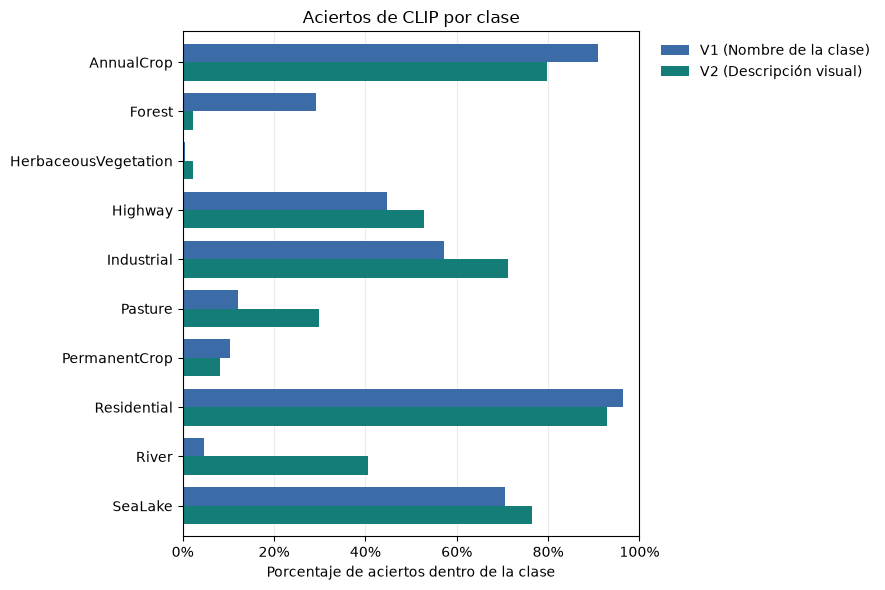

In [44]:
from matplotlib.ticker import PercentFormatter

class_results = pd.DataFrame({
    "Clase": predictions["class_name"],
    "V1 (Nombre de la clase)": correct_v1,
    "V2 (Descripción visual)": correct_v2,
})

accuracy_by_class = (
    class_results.groupby("Clase")
    .mean()
    .mul(100)
    .reindex(class_names)
)

ax = accuracy_by_class.plot.barh(
    figsize=(9, 6),
    color=["#3B6CA8", "#147D78"],
    width=0.75,
)

ax.invert_yaxis()
ax.set_title("Aciertos de CLIP por clase")
ax.set_xlabel("Porcentaje de aciertos dentro de la clase")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)

plt.tight_layout()
plt.show()

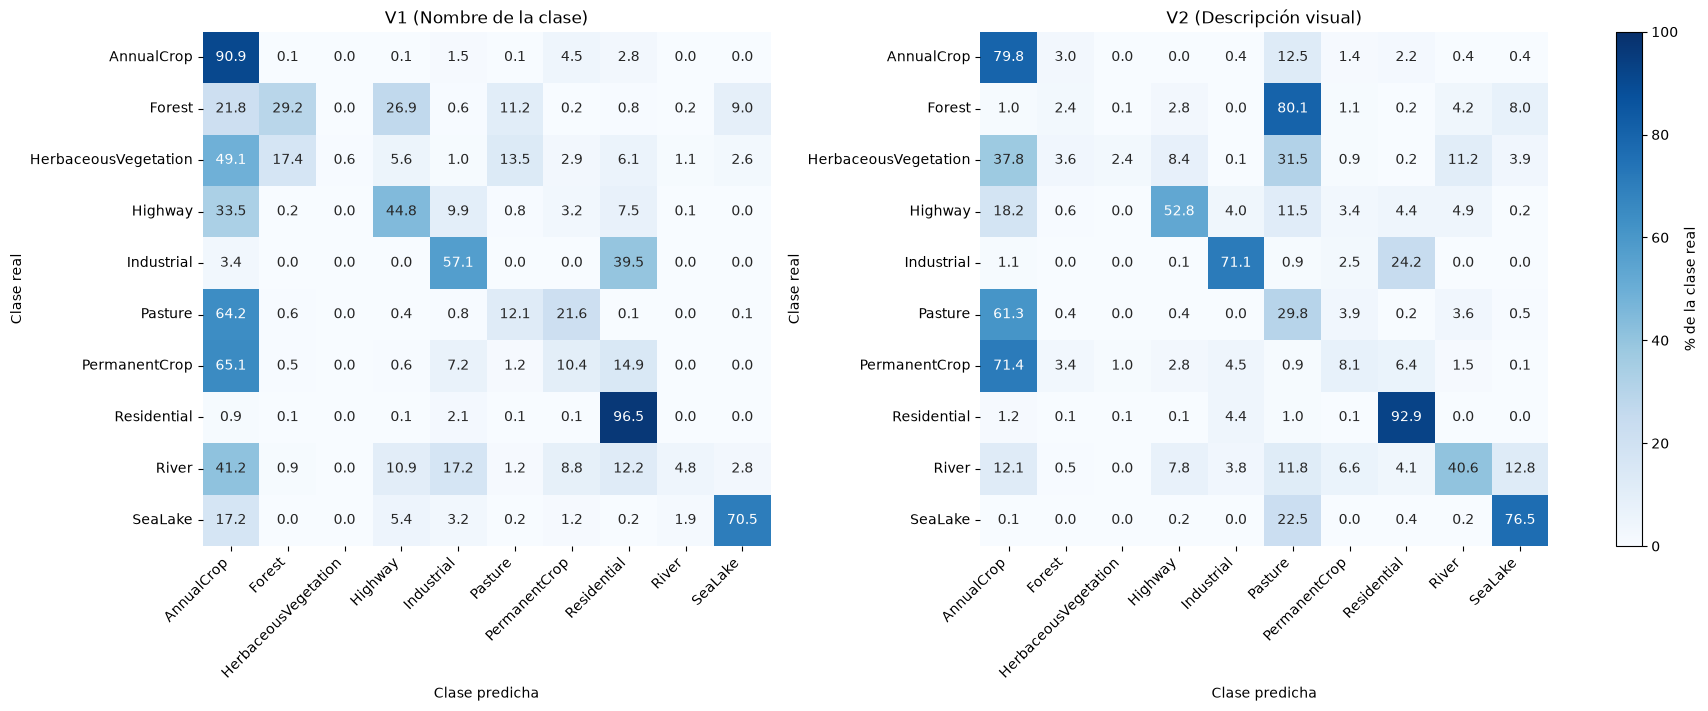

In [45]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

matrix_v1 = confusion_matrix(
    predictions["class_name"],
    predictions["pred_v1"],
    labels=class_names,
    normalize="true",
) * 100

matrix_v2 = confusion_matrix(
    predictions["class_name"],
    predictions["pred_v2"],
    labels=class_names,
    normalize="true",
) * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 7), layout="constrained")

for ax, matrix, title in zip(
    axes,
    [matrix_v1, matrix_v2],
    ["V1 (Nombre de la clase)", "V2 (Descripción visual)"],
):
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".1f",
        cmap="Blues",
        vmin=0,
        vmax=100,
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=False,
        ax=ax,
    )
    ax.set(title=title, xlabel="Clase predicha", ylabel="Clase real")
    ax.tick_params(axis="y", labelrotation=0)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

fig.colorbar(axes[0].collections[0], ax=axes, label="% de la clase real")
plt.show()

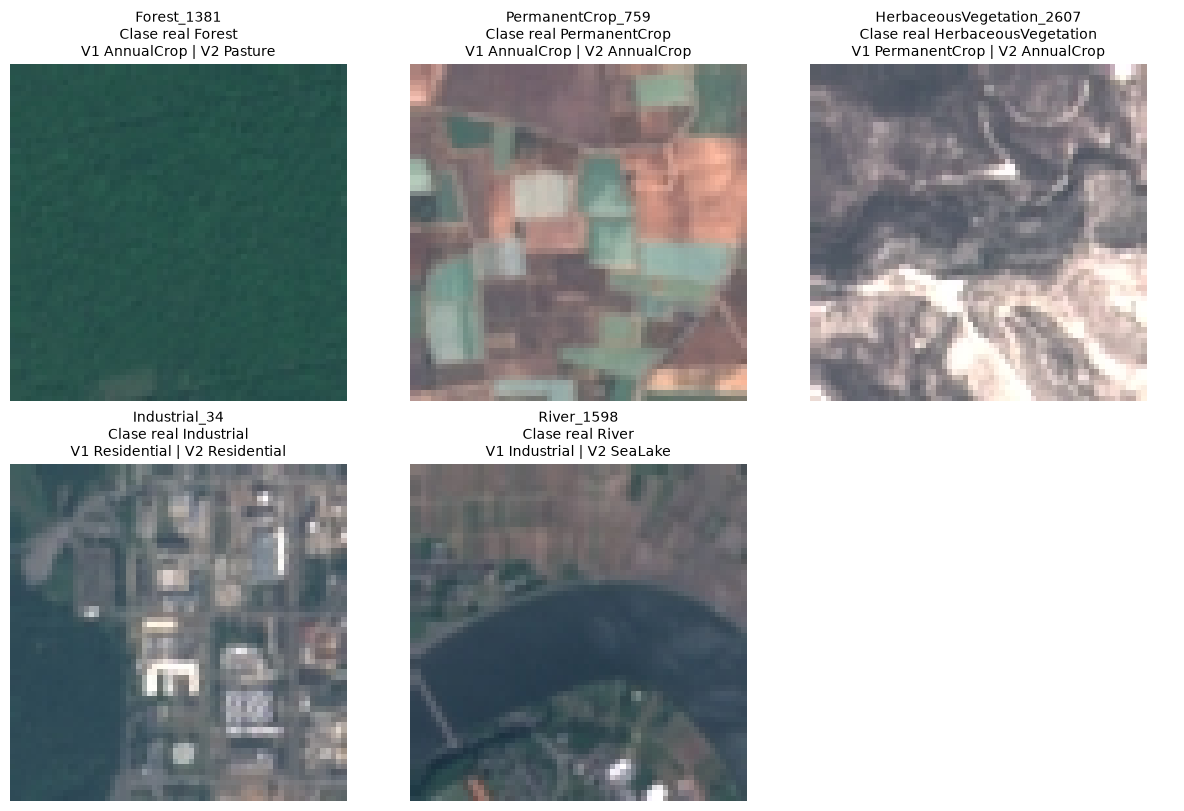

In [47]:
confusion_pairs = [
    ("Forest", "Pasture"),
    ("PermanentCrop", "AnnualCrop"),
    ("HerbaceousVegetation", "AnnualCrop"),
    ("Industrial", "Residential"),
    ("River", "SeaLake"),
]

selected_errors = []

for true_class, predicted_class in confusion_pairs:
    candidates = predictions[
        (predictions["class_name"] == true_class)
        & (predictions["pred_v2"] == predicted_class)
    ]
    selected_errors.append(candidates.sample(n=1, random_state=42))

error_examples = pd.concat(selected_errors, ignore_index=True)

fig, axes = plt.subplots(2, 3, figsize=(12, 8), layout="constrained")

for ax in axes.flat:
    ax.axis("off")

for ax, row in zip(axes.flat, error_examples.itertuples(index=False)):
    image_path = RGB_DIR / row.class_name / f"{row.patch_id}.jpg"

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"{row.patch_id}\n"
        f"Clase real {row.class_name}\n"
        f"V1 {row.pred_v1} | V2 {row.pred_v2}",
        fontsize=10,
    )

plt.show()